In [1]:
import pandas as pd
from h3 import h3
import glob
import numpy as np
from pandas import merge
import json
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import shape
from datetime import datetime, timedelta
import seaborn as sns

In [2]:
# Pandas Config
pd.set_option('display.max_columns', None)

# Spatial Resolution
H3_HEXAGON_RESOLUTION = 7 # 8 <=> ~460 meter edge length ~ 0.7373276m^2 area <=> circle with 500 meter radius

# ShareNow Data 
VEHICLE_TRIP = '/Users/demircanm/sciebo/IS3/Research_Projects/EmpiricalAnalysisSharedMobility/02_Data/final_dataset.csv'

# TIMEZONE
TIMEZONE = 'Europe/Berlin'



In [4]:
# Read Trips
trips = pd.read_csv(VEHICLE_TRIP)

/Users/demircanm/opt/anaconda3/envs/SharedMobility/lib/python3.7/site-packages/IPython/core/interactiveshell.py:3146: DtypeWarning: Columns (4,21,22,114) have mixed types.Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


In [5]:
trips

,id,provider,city,vehicleType,model,datetime_start,date_start,time_start,datetime_end,date_end,time_end,longitude_start,latitude_start,longitude_end,latitude_end,fuel_start,fuel_end,distance,duration,price_driving_start,price_driving_end,price_promo_start,price_promo_end,idle_duration,geometry,missing_file_number,h3_9,tier,emio,callabike,bmw 2er active tourer,bmw 2er cabrio,bmw x2,mercedes-benz gla,bmw x1,mercedes-benz a-klasse,mini 3-tuerer,mini 5-tuerer,mini cabrio,mini clubman,mini countryman,mercedes-benz b-klasse,bmw i3,smart fortwo 3rd generation,bmw 1er,nextbike,low quality vehicle,medium quality vehicle,premium quality vehicle,month,dayofweek,time_bucket,weekend,week,is_holiday,sharenow_postmerger,hex_start,hex_end,elevation_change,ascent,descent,start_d2c,end_d2c,d2c_change,d2c_direction,orig_clc,dest_clc,orig_level_1,orig_level_2,orig_level_3,dest_level_1,dest_level_2,dest_level_3,Bezirk,Bevölkerung,Alter unter 15,Alter 15 – 45,Alter 45 – 65,Alter 65 und mehr,Erwerbspersonen / Erwerbstätige,Erwerbspersonen / Erwerbslose,Nicht erwerbspersonen,Bevölkerung / Monatliches Nettoeinkommen unter 900,Bevölkerung / Monatliches Nettoeinkommen 900 – 1500,Bevölkerung / Monatliches Nettoeinkommen 1500 und mehr,Erwerbstätige / Monatliches Nettoeinkommen unter 900,Erwerbstätige / Monatliches Nettoeinkommen 900 – 1500,Erwerbstätige / Monatliches Nettoeinkommen 1500 und mehr,Rechtliche Einheiten,Sozialversicherungspflichtig Beschäftigte 2018,Umsatz 2018 (EUR),Studierende 2019,Bevölkerung mit Migrationshintergrund 2018,Ledig,Verheiratet,Geschieden,Verwitwet,Eingetr. Lebenspartnerschaft,Ohne Angabe,Eingetr. Lebenspartnerschaft aufgehoben,Eingetr. Lebenspartner/-in verstorben,Unter 18,30 - 49,65 und älter,18 - 29,50 - 64,Einheiten insgesamt,total_households,Einpersonenhaushalte (Singlehaushalte),Paare ohne Kind(er),Alleinerziehende Elternteile,Paare mit Kind(ern),Mehrpersonenhaushalte ohne Kernfamilie,temp,precipitation,shopping_start,shopping_end,food_start,food_end,health_start,health_end,transport_start,transport_end,services_start,services_end,outdoor_start,outdoor_end,leisure_and_entertainment_start,leisure_and_entertainment_end,civil_services_start,civil_services_end,h3_8,h3_7,discrete_count_9,discrete_count_8,discrete_count_7,provider_merged,provider_fleetsize_weekly
0,13001nextbike,nextbike,berlin,bycicle,NaN,2019-10-04 15:08:00+02:00,20191004,1505,2019-10-04 15:36:00+02:00,20191004,1535,13.433009,52.491855,13.455552,52.474241,NaN,NaN,2483.191423,1680.0,1€/30 min,1€/30 min,NaN,NaN,74160.0,POINT (13.43300933 52.49185470000001),0.0,617540520298414079,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,10,4,"[1200, 1600)",False,40,False,False,891f1d4d2cbffff,891f18b2c53ffff,8.040052,41.950200,33.910148,2325.360620,4699.074974,2373.714355,outbound,111,121,Artificial surfaces,Urban fabric,Continuous urban fabric,Artificial surfaces,"Industrial, commercial and transport units",Industrial or commercial units,Neukölln,319991.4,43992.3,139093.7,80299.7,56605.7,150900.0,16100.0,153000.0,76300.0,88700.0,98300.0,24300.0,49800.0,76400.0,12182.0,54090.0,7254056.0,13863.640,133300.0,29.0,7.0,0.0,0.0,3.0,0.0,0.0,0.0,3.0,22.0,0.0,12.0,3.0,40.0,26.0,16.0,4.0,0.0,3.0,3.0,11.1,False,297620.353465,1.135088e+05,513243.862851,136989.751109,169041.385969,98897.816916,445937.965278,365919.171830,268224.617277,105714.368842,268159.174652,197875.392843,297058.391781,164115.290806,356447.181396,324323.585487,613036920672354303,608533321047080959,4,37,163,nextbike,934
1,13001nextbike,nextbike,berlin,bycicle,NaN,2019-10-06 20:48:00+02:00,20191006,2045,2019-10-06 20:56:00+02:00,20191006,2055,13.436258,52.483282,13.442753,52.480588,NaN,NaN,532.205170,480.0,1€/30 min,1€/30 min,NaN,NaN,65700.0,POINT (13.4362577 52.4832825),0.0,617540203794661375,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,10,6,"[2000, 2400)",True,40,False,False,891f18b21b3ffff,891f18b21a3ffff,-6.006853,0.000000,6.0068

In [6]:
# Hex 9 
trips["hex_start"]

0          891f1d4d2cbffff
1          891f18b21b3ffff
2          891f18b21a3ffff
3          891f1d48b73ffff
4          891f18b24a7ffff
                ...       
2636181    891f1d489abffff
2636182    891f1d489abffff
2636183    891f1d48ebbffff
2636184    891f1d48ebbffff
2636185    891f1d48ebbffff
Name: hex_start, Length: 2636186, dtype: object

In [7]:
# Convert to H3 Hex ID
import h3._cy as c
trips["h3_8"] = trips["h3_8"].apply(lambda row: c.int2hex(row))
trips["h3_9"] = trips["h3_9"].apply(lambda row: c.int2hex(row))


### Get Hexagons H9

In [143]:
# convert h3 id to geometry
from shapely.geometry import Polygon
 
def add_geometry(hex_id):
    points = h3.h3_to_geo_boundary(
      hex_id, True)
    return Polygon(points)

In [144]:
hexagons = trips["hex_start"]

In [145]:
hexagons = pd.DataFrame(hexagons.unique(), columns = ["hex_id"])

In [146]:
hexagons["geometry"] = hexagons.apply(lambda row: add_geometry(row["hex_id"]), axis=1)

In [147]:
gdf = gpd.GeoDataFrame(hexagons, crs='EPSG:4326')

In [153]:
# Bounding Box of Environment
environment = pd.DataFrame(["environment"], columns = ["id"])
environment["geometry"] = gdf.geometry.unary_union.envelope
environment_gpd = gpd.GeoDataFrame(environment, crs='EPSG:4326')

In [162]:
# Bounding Box to GeoJSON using Hex 9 (as required by polyfill)
import json

env_json  = environment_gpd.to_json()

env_json  = json.loads(env_json)

env_json  = env_json["features"][0]["geometry"]

# Hex 9
env_hex_9 = pd.DataFrame(h3.polyfill_geojson(env_json, 9), columns = ["hex_id_9"])

env_hex_9["geometry"] = env_hex_9.apply(lambda row: add_geometry(row["hex_id_9"]), axis=1)

env_hex_9_gdf = gpd.GeoDataFrame(env_hex_9, crs='EPSG:4326')

# Hex 8
env_hex_8 = pd.DataFrame(h3.polyfill_geojson(env_json, 8), columns = ["hex_id_8"])

env_hex_8["geometry"] = env_hex_8.apply(lambda row: add_geometry(row["hex_id_8"]), axis=1)

env_hex_8_gdf = gpd.GeoDataFrame(env_hex_8, crs='EPSG:4326')

# Hex 7
env_hex_7 = pd.DataFrame(h3.polyfill_geojson(env_json, 7), columns = ["hex_id_7"])

env_hex_7["geometry"] = env_hex_7.apply(lambda row: add_geometry(row["hex_id_7"]), axis=1)

env_hex_7_gdf = gpd.GeoDataFrame(env_hex_7, crs='EPSG:4326')

In [169]:
# Safe Environment Files

In [168]:
environment_gpd.to_file("env_bounding_box.geojson", driver='GeoJSON')
env_hex_9_gdf.to_file("env_hex_9.geojson", driver='GeoJSON')
env_hex_8_gdf.to_file("env_hex_8.geojson", driver='GeoJSON')
env_hex_7_gdf.to_file("env_hex_7.geojson", driver='GeoJSON')

In [193]:
from shapely.geometry import shape

from shapely.geometry import Point
test =gpd.GeoDataFrame([Point(15.3, 54.5)], columns = ["geometry"])


<AxesSubplot:>

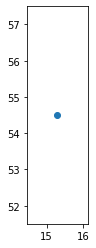

In [194]:
test.plot()